# Spurs Women in the FA WSL: an xG and Chance-Creation Analysis

**Author:** Anthony Adusei-Poku · MSc Data Science (University of East London, 2025)

**Question:** how did Tottenham Hotspur Women's chance creation and chance prevention compare with the rest of the FA WSL in 2023/24, how had that changed since their first two top-flight seasons (2019/20 and 2020/21), and which players drove it?

This is my existing xG model ([football-xg-model](https://github.com/anthony07-max/football-xg-model)) and player-profile method ([football-scouting-tool](https://github.com/anthony07-max/football-scouting-tool)) applied to Spurs Women. In this notebook I:

1. Check what WSL match coverage StatsBomb Open Data actually has for 2018/19, 2019/20, 2020/21 and 2023/24 (the WSL seasons in the open data).
2. Re-train my xG model exactly as in the original repo (men's shots only) and test how well it transfers to WSL shots, against StatsBomb's own xG.
3. Compare Spurs' non-penalty xG for and against, shot quality and chance creation with every other WSL team, using league ranks.
4. Build per-90 player profiles and draw percentile radars for six Spurs players from 2023/24 against WSL players in the same position group.

> **Data:** StatsBomb Open Data, © StatsBomb, used under the [StatsBomb Open Data licence](https://github.com/statsbomb/open-data/blob/master/LICENSE.pdf). Thanks to StatsBomb for making it freely available. The newest season in the open data is 2023/24 (to May 2024), so this describes those seasons, not the current squad.

In [1]:
# --- Setup -----------------------------------------------------------------
import os, sys, json, subprocess, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from sklearn.metrics import log_loss, brier_score_loss, roc_auc_score
from mplsoccer import VerticalPitch, Radar

warnings.filterwarnings("ignore")
sys.path.insert(0, "src")
from features import load_shots
from xg_model import train_xg_model, predict_xg
import wsl

SEED = 42
FIG_DIR = "figures"; os.makedirs(FIG_DIR, exist_ok=True)
RES_DIR = "results"; os.makedirs(RES_DIR, exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 10, "font.family": "DejaVu Sans"})
SPURS_NAVY, LEAGUE_GREY, AGAINST_RED = "#132257", "#b0b0b0", "#c0392b"
SEASONS = ["2019/20", "2020/21", "2023/24"]   # Spurs' WSL seasons in the data
LATEST = "2023/24"
KEY = {}                           # headline numbers, saved to results/key_numbers.json
def save(fig, name):
    fig.savefig(os.path.join(FIG_DIR, name), facecolor="white")

## 1. Data and coverage

`src/download_wsl.py` reads every WSL match and event file for 2018/19, 2019/20, 2020/21 and 2023/24 from the StatsBomb open-data GitHub repository and writes compact tables (shots, team-match and player-match counts). `src/download_training_shots.py` downloads the men's shots that the xG model is trained on (the same competitions as football-xg-model). Raw data is not committed; the cell below recreates it if it is missing.

In [2]:
if not os.path.exists("data/wsl/team_match.parquet"):
    subprocess.run([sys.executable, "src/download_wsl.py"], check=True)
if not os.path.exists("data/train_shots") or len(os.listdir("data/train_shots")) < 27:
    subprocess.run([sys.executable, "src/download_training_shots.py"], check=True)

matches, team_match, player_match = wsl.load_tables()
# Matches played in each season (11 teams in 2018/19, 12 after; 2019/20 was curtailed by COVID-19
# in March 2020 after 87 matches, and the FA decided the table on points per game).
PLAYED = {"2018/19": 110, "2019/20": 87, "2020/21": 132, "2023/24": 132}
cov = (matches.assign(spurs=(matches.home_team == wsl.SPURS) | (matches.away_team == wsl.SPURS))
       .groupby("season").agg(matches_in_data=("match_id", "size"), spurs_matches=("spurs", "sum"),
                              teams=("home_team", "nunique")))
cov["matches_played"] = cov.index.map(PLAYED)
cov["coverage"] = (cov.matches_in_data / cov.matches_played).map("{:.0%}".format)
cov["spurs_played"] = cov.index.map({"2018/19": 0, "2019/20": 15, "2020/21": 22, "2023/24": 22})
cov = cov[["teams", "matches_played", "matches_in_data", "coverage", "spurs_played", "spurs_matches"]]
cov.to_csv(os.path.join(RES_DIR, "coverage.csv"))
KEY["coverage"] = cov.reset_index().to_dict("records")
cov

,teams,matches_played,matches_in_data,coverage,spurs_played,spurs_matches
season,,,,,,
2018/19,11,110,107,97%,0,0
2019/20,12,87,87,100%,15,15
2020/21,12,132,131,99%,22,21
2023/24,12,132,132,100%,22,22


In [3]:
spurs_m = matches[(matches.home_team == wsl.SPURS) | (matches.away_team == wsl.SPURS)]
played_2021 = team_match[(team_match.season == "2020/21")]
opp_count = played_2021[played_2021.team == wsl.SPURS].opponent.value_counts()
print("Spurs 2020/21 opponents met only once in the data:", list(opp_count[opp_count == 1].index))
print("Note: StatsBomb uses two names for some clubs (e.g. 'Manchester United' and 'Manchester United W');"
      " src/wsl.py maps them to one.")

Spurs 2020/21 opponents met only once in the data: ['Birmingham City']
Note: StatsBomb uses two names for some clubs (e.g. 'Manchester United' and 'Manchester United W'); src/wsl.py maps them to one.


## 2. The xG model: re-trained, then applied to WSL shots

`src/xg_model.py` copies the features, filters, LightGBM settings and match-based split from football-xg-model. **It is trained only on men's shots** (big-five leagues 2015/16, men's international tournaments and the La Liga Messi seasons). No WSL shot is used in training, so every WSL prediction is out of sample. The first check is that the re-trained model matches the original repo's held-out test metrics (log loss 0.2584, Brier 0.0734, ROC AUC 0.809). Shots are sorted before training so every run gives the same model; because LightGBM's row subsampling depends on row order, the numbers differ very slightly from the original.

In [4]:
bundle = train_xg_model("data/train_shots")
tm_ = bundle["test_metrics"]
print(f"Trained on {bundle['n_train_shots']:,} men's non-penalty shots from {bundle['n_train_matches']:,} matches "
      f"({bundle['best_iteration']} trees)")
print(f"Men's held-out test set ({tm_['shots']:,} shots, {tm_['matches']} matches): log loss {tm_['log_loss']:.4f}, "
      f"Brier {tm_['brier']:.4f}, ROC AUC {tm_['roc_auc']:.3f}  (StatsBomb: {tm_['sb_log_loss']:.4f}, AUC {tm_['sb_roc_auc']:.3f})")
print(f"Penalties are valued at the men's in-game conversion rate: {bundle['pen_xg']:.3f}")
KEY["model"] = {"train_shots": bundle["n_train_shots"], "train_matches": bundle["n_train_matches"],
                "mens_test": {k: round(v, 4) for k, v in tm_.items()}}

Trained on 57,664 men's non-penalty shots from 2,351 matches (188 trees)
Men's held-out test set (11,585 shots, 471 matches): log loss 0.2591, Brier 0.0736, ROC AUC 0.807  (StatsBomb: 0.2577, AUC 0.811)
Penalties are valued at the men's in-game conversion rate: 0.760


In [5]:
shots = (load_shots("data/wsl/shots")   # sorted so tables and plots do not depend on download order
         .sort_values(["match_id", "period", "minute", "shot_id"]).reset_index(drop=True))
shots["team"] = shots.team.map(wsl.short_team)
shots["season"] = shots.competition.str[-7:]
shots["xg"] = predict_xg(bundle, shots)
# The opponent of each shot, for "xG against"
side = matches.set_index("match_id")
shots["opponent"] = np.where(shots.team == shots.match_id.map(side.home_team),
                             shots.match_id.map(side.away_team), shots.match_id.map(side.home_team))
np_shots = shots[(shots.shot_type != "Penalty") & (shots.period <= 4)].copy()
print(f"{len(shots):,} WSL shots ({len(np_shots):,} non-penalty) from {shots.match_id.nunique()} matches; "
      f"{(shots.shot_type == 'Penalty').sum()} penalties ({shots.loc[shots.shot_type == 'Penalty', 'is_goal'].mean():.1%} scored)")
print(f"Shots with a freeze frame: {np_shots.has_freeze_frame.mean():.1%}")

11,816 WSL shots (11,711 non-penalty) from 457 matches; 105 penalties (74.3% scored)
Shots with a freeze frame: 100.0%


### How well does a men's model transfer to the WSL?

Scored on all WSL non-penalty shots, with a 1,000-sample bootstrap over matches for the difference in log loss. StatsBomb's xG is the benchmark.

In [6]:
y = np_shots.is_goal.values
def metrics(p):
    return {"log_loss": log_loss(y, p), "brier": brier_score_loss(y, p), "roc_auc": roc_auc_score(y, p),
            "total_xg": p.sum()}
wm = pd.DataFrame({"My model (trained on men's shots)": metrics(np_shots.xg.values),
                   "StatsBomb xG": metrics(np_shots.statsbomb_xg.values)}).T
wm["actual_goals"] = y.sum()

# Paired bootstrap over matches for the log-loss difference (mine minus StatsBomb)
rng = np.random.default_rng(SEED)
ll_m = -(y * np.log(np_shots.xg) + (1 - y) * np.log(1 - np_shots.xg))
ll_s = -(y * np.log(np_shots.statsbomb_xg) + (1 - y) * np.log(1 - np_shots.statsbomb_xg))
per = pd.DataFrame({"m": ll_m.values, "s": ll_s.values, "match": np_shots.match_id.values}).groupby("match").agg(["sum", "size"])
ids = np.arange(len(per)); diffs = []
for _ in range(1000):
    b = rng.choice(ids, len(ids))
    diffs.append(per[("m", "sum")].values[b].sum() / per[("m", "size")].values[b].sum()
                 - per[("s", "sum")].values[b].sum() / per[("s", "size")].values[b].sum())
lo, hi = np.percentile(diffs, [2.5, 97.5])
r = np.corrcoef(np_shots.xg, np_shots.statsbomb_xg)[0, 1]
print(f"Log-loss difference (mine - StatsBomb): {wm.iloc[0].log_loss - wm.iloc[1].log_loss:+.4f} "
      f"(95% CI {lo:+.4f} to {hi:+.4f}); shot-level correlation r = {r:.3f}")
wm.to_csv(os.path.join(RES_DIR, "wsl_model_metrics.csv"))
KEY["wsl_model"] = {"shots": int(len(np_shots)), "goals": int(y.sum()),
                    "mine": {k: round(float(v), 4) for k, v in wm.iloc[0].items()},
                    "statsbomb": {k: round(float(v), 4) for k, v in wm.iloc[1].items()},
                    "ll_diff_ci": [round(lo, 4), round(hi, 4)], "r": round(r, 3)}
wm.round(4)

Log-loss difference (mine - StatsBomb): -0.0036 (95% CI -0.0074 to +0.0000); shot-level correlation r = 0.913


,log_loss,brier,roc_auc,total_xg,actual_goals
My model (trained on men's shots),0.2915,0.0839,0.7799,1279.4139,1300
StatsBomb xG,0.2951,0.0836,0.7746,1230.0186,1300


In [7]:
by_season = np_shots.groupby("season").agg(shots=("is_goal", "size"), goals=("is_goal", "sum"),
                                           my_xg=("xg", "sum"), statsbomb_xg=("statsbomb_xg", "sum")).round(1)
by_season

,shots,goals,my_xg,statsbomb_xg
season,,,,
2018/19,2792,292,308.6,281.9
2019/20,2201,237,224.8,220.8
2020/21,3212,369,362.0,352.2
2023/24,3506,402,384.0,375.1


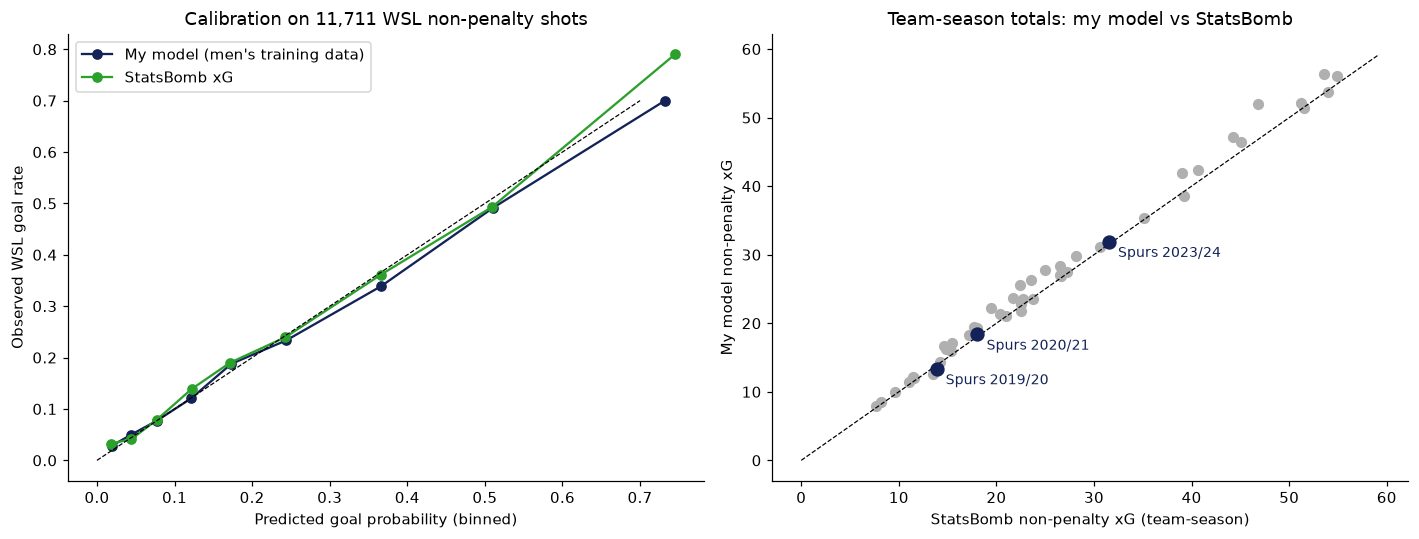

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
bins = [0, .03, .06, .1, .15, .2, .3, .45, .6, 1]
for col, lab, c in [("xg", "My model (men's training data)", SPURS_NAVY), ("statsbomb_xg", "StatsBomb xG", "#2ca02c")]:
    b = pd.cut(np_shots[col], bins)
    cal = np_shots.groupby(b, observed=True).agg(pred=(col, "mean"), obs=("is_goal", "mean"), n=("is_goal", "size"))
    axes[0].plot(cal.pred, cal.obs, "o-", color=c, label=lab)
axes[0].plot([0, .7], [0, .7], "k--", lw=0.8)
axes[0].set(xlabel="Predicted goal probability (binned)", ylabel="Observed WSL goal rate",
            title=f"Calibration on {len(np_shots):,} WSL non-penalty shots")
axes[0].legend()

ts_cmp = (np_shots.groupby(["season", "team"]).agg(mine=("xg", "sum"), sb=("statsbomb_xg", "sum"))
          .reset_index())
axes[1].scatter(ts_cmp.sb, ts_cmp.mine, color=LEAGUE_GREY, s=40)
sp = ts_cmp[ts_cmp.team == wsl.SPURS]
axes[1].scatter(sp.sb, sp.mine, color=SPURS_NAVY, s=70, zorder=3)
for _, rw in sp.iterrows():
    axes[1].annotate(f"Spurs {rw.season}", (rw.sb, rw.mine), xytext=(6, -10), textcoords="offset points",
                     color=SPURS_NAVY, fontsize=9)
lim = [0, ts_cmp[["mine", "sb"]].max().max() * 1.05]
axes[1].plot(lim, lim, "k--", lw=0.8)
axes[1].set(xlabel="StatsBomb non-penalty xG (team-season)", ylabel="My model non-penalty xG",
            title="Team-season totals: my model vs StatsBomb")
fig.tight_layout(); save(fig, "01_model_vs_statsbomb.png"); plt.show()

## 3. Team level: Spurs against the rest of the league

All team numbers below are **per match**, use **non-penalty xG from my model** (StatsBomb xG is kept alongside as a check) and are ranked within each season (1 = best; for "against" metrics, 1 = conceded least). Definitions:

* **Key passes:** open-play passes that lead directly to a shot.
* **Shot-creating actions (SCA):** the two attacking actions directly before each non-penalty shot in the same possession (completed passes, including set pieces; completed dribbles; fouls won; and a shot that leads to a rebound shot), following FBref's definition.
* **Progressive passes:** completed open-play passes, starting outside the defensive 30 yards, that move the ball at least 25% (and at least 5 yards) closer to the centre of goal.

In [9]:
g = np_shots.groupby(["match_id", "team"]).agg(npxg=("xg", "sum"), sb_npxg=("statsbomb_xg", "sum"),
                                               np_goals=("is_goal", "sum")).reset_index()
tmx = team_match.merge(g, on=["match_id", "team"], how="left").fillna({"npxg": 0, "sb_npxg": 0, "np_goals": 0})
ts = wsl.team_season_table(tmx)
ts.round(3).to_csv(os.path.join(RES_DIR, "team_season_table.csv"), index=False)

show = ["matches", "points", "goals", "goals_against", "npxg_pm", "npxg_against_pm", "npxgd_pm",
        "shots_pm", "shots_against_pm", "xg_per_shot", "xg_per_shot_against", "key_passes_pm",
        "sca_pm", "prog_passes_pm", "possession", "np_goals_minus_xg", "np_goals_against_minus_xg"]
spurs_ts = ts[ts.team == wsl.SPURS].set_index("season")
KEY["spurs_team"] = {s: {k: (round(float(v), 3) if isinstance(v, (float, np.floating)) else int(v))
                         for k, v in spurs_ts.loc[s].drop("team").items()} for s in spurs_ts.index}
spurs_ts[show].T.round(3)

season,2019/20,2020/21,2023/24
matches,15.000,21.000,22.000
points,20.000,17.000,31.000
goals,15.000,18.000,31.000
goals_against,24.000,41.000,36.000
npxg_pm,0.889,0.875,1.450
npxg_against_pm,1.784,1.426,1.354
npxgd_pm,-0.895,-0.551,0.096
shots_pm,12.000,9.333,13.818
shots_against_pm,17.067,13.143,13.227
xg_per_shot,0.074,0.094,0.105


In [10]:
rank_cols = {"npxg_pm": "npxG for", "npxg_against_pm": "npxG against", "npxgd_pm": "npxG difference",
             "shots_pm": "Shots for", "shots_against_pm": "Shots against", "xg_per_shot": "xG per shot",
             "xg_per_shot_against": "xG per shot against", "key_passes_pm": "Key passes",
             "sca_pm": "Shot-creating actions", "prog_passes_pm": "Progressive passes",
             "box_receipts_pm": "Touches received in box", "possession": "Possession (pass share)",
             "points_pm": "Points per match"}
ranks = spurs_ts[[c + "_rank" for c in rank_cols]].T
ranks.index = list(rank_cols.values())
print("Spurs' rank out of 12 in each season")
ranks

Spurs' rank out of 12 in each season


season,2019/20,2020/21,2023/24
npxG for,8,9,5
npxG against,10,6,6
npxG difference,11,7,5
Shots for,6,9,5
Shots against,11,6,6
xG per shot,11,10,7
xG per shot against,8,7,5
Key passes,6,9,4
Shot-creating actions,6,9,5
Progressive passes,11,9,6


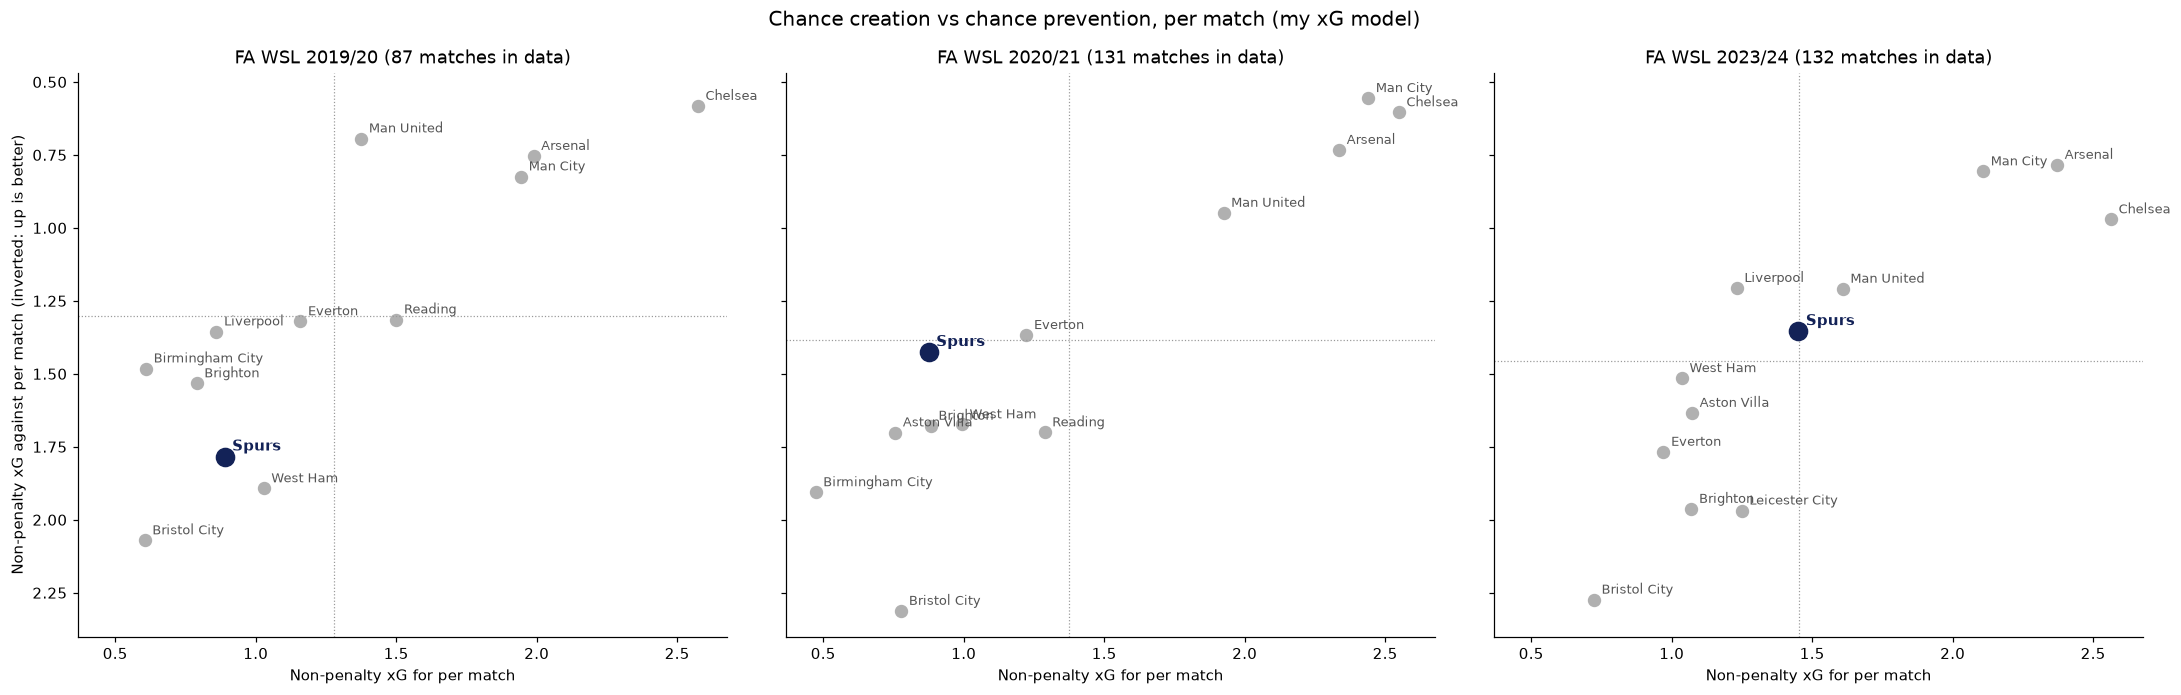

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6.4), sharex=True, sharey=True)
for ax, season in zip(axes, SEASONS):
    d = ts[ts.season == season]
    ax.scatter(d.npxg_pm, d.npxg_against_pm, s=60, color=LEAGUE_GREY, zorder=2)
    for _, rw in d.iterrows():
        sp = rw.team == wsl.SPURS
        ax.annotate(rw.team, (rw.npxg_pm, rw.npxg_against_pm), xytext=(5, 4), textcoords="offset points",
                    fontsize=10 if sp else 8.5, color=SPURS_NAVY if sp else "#555555",
                    fontweight="bold" if sp else "normal")
    s = d[d.team == wsl.SPURS]
    ax.scatter(s.npxg_pm, s.npxg_against_pm, s=140, color=SPURS_NAVY, zorder=3)
    ax.axvline(d.npxg_pm.mean(), color="#999999", lw=0.8, ls=":")
    ax.axhline(d.npxg_against_pm.mean(), color="#999999", lw=0.8, ls=":")
    ax.set(title=f"FA WSL {season} ({d.matches.sum() // 2} matches in data)",
           xlabel="Non-penalty xG for per match")
    ax.invert_yaxis()
axes[0].set_ylabel("Non-penalty xG against per match (inverted: up is better)")
fig.suptitle("Chance creation vs chance prevention, per match (my xG model)", fontsize=13)
fig.tight_layout(); save(fig, "02_league_xg_scatter.png"); plt.show()

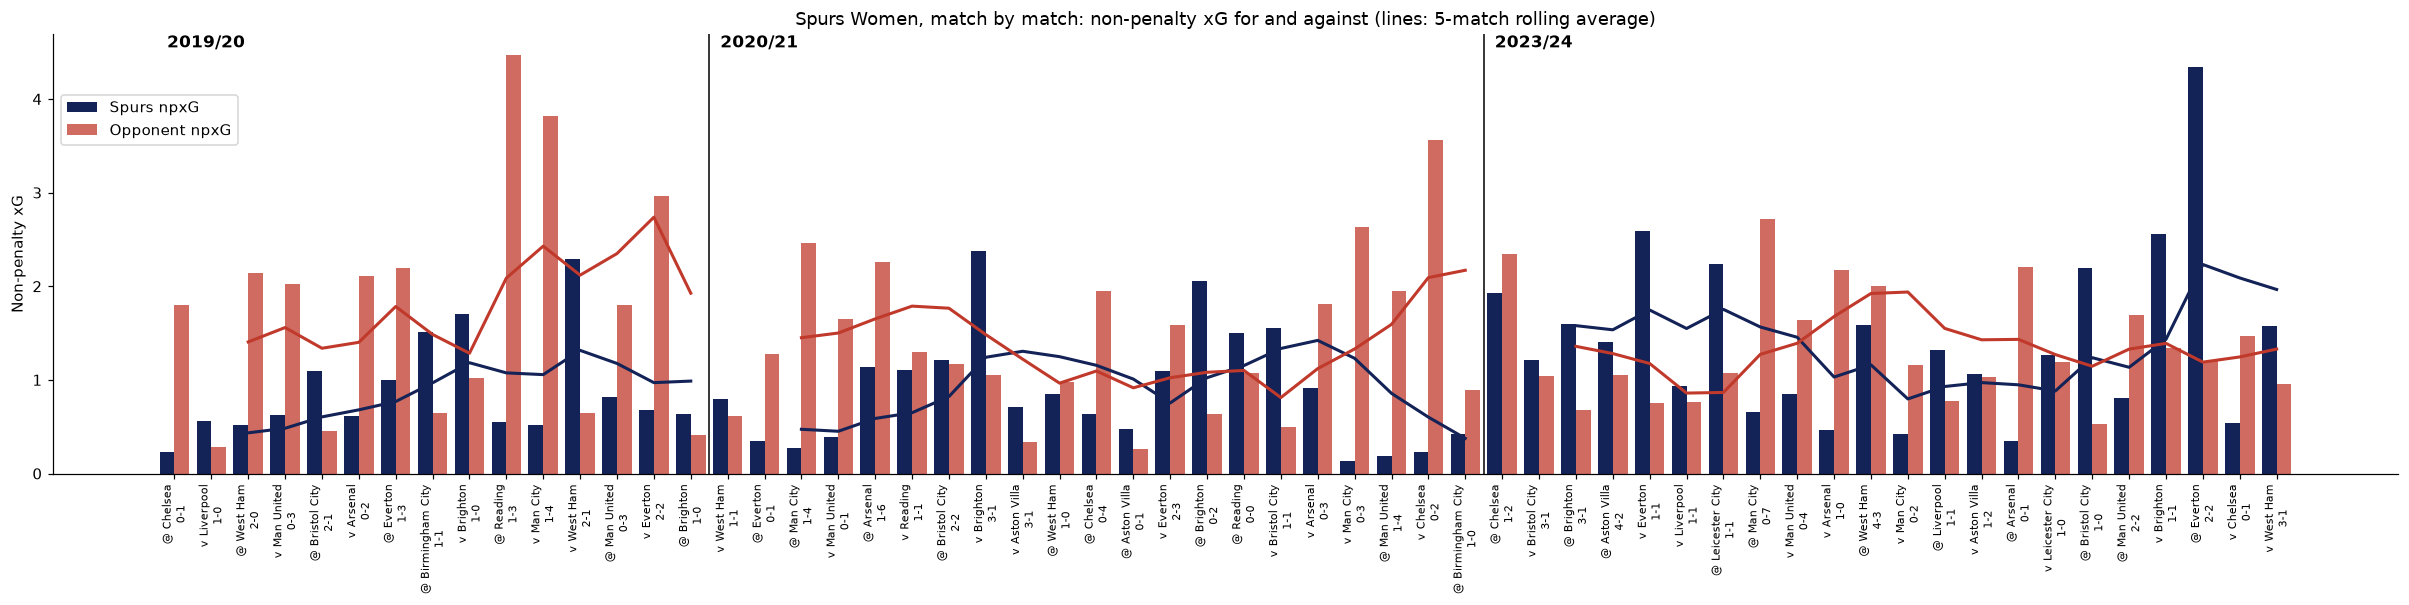

In [12]:
sm = tmx.merge(tmx[["match_id", "team", "npxg", "goals"]].rename(columns={"team": "opponent", "npxg": "npxg_against",
                                                                          "goals": "goals_against"}),
               on=["match_id", "opponent"])
sm = sm[sm.team == wsl.SPURS].sort_values("match_date").reset_index(drop=True)
sm["result"] = np.select([sm.goals > sm.goals_against, sm.goals == sm.goals_against], ["W", "D"], "L")
sm[["season", "match_date", "opponent", "home", "goals", "goals_against", "npxg", "npxg_against", "result"]] \
    .round(3).to_csv(os.path.join(RES_DIR, "spurs_matches.csv"), index=False)

fig, ax = plt.subplots(figsize=(22, 5.6))
x = np.arange(len(sm))
ax.bar(x - 0.2, sm.npxg, 0.4, color=SPURS_NAVY, label="Spurs npxG")
ax.bar(x + 0.2, sm.npxg_against, 0.4, color=AGAINST_RED, alpha=0.75, label="Opponent npxG")
for season in SEASONS:
    idx = sm.index[sm.season == season]
    roll_f = sm.loc[idx, "npxg"].rolling(5, min_periods=3).mean()
    roll_a = sm.loc[idx, "npxg_against"].rolling(5, min_periods=3).mean()
    ax.plot(idx, roll_f, color=SPURS_NAVY, lw=2)
    ax.plot(idx, roll_a, color=AGAINST_RED, lw=2)
for season in SEASONS:
    first = sm.index[sm.season == season][0]
    if first > 0:
        ax.axvline(first - 0.5, color="black", lw=1)
    ax.text(first - 0.2, ax.get_ylim()[1] * 0.97, season, ha="left", fontsize=11, fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels([f"{'v' if h else '@'} {o}\n{gf}-{ga}" for o, h, gf, ga in
                    zip(sm.opponent, sm.home, sm.goals, sm.goals_against)], rotation=90, fontsize=7.5)
ax.set_ylabel("Non-penalty xG")
ax.set_title("Spurs Women, match by match: non-penalty xG for and against (lines: 5-match rolling average)")
ax.legend(loc="upper left", bbox_to_anchor=(0.0, 0.88))
fig.tight_layout(); save(fig, "03_spurs_match_xg.png"); plt.show()

### Shot quality

xG per shot separates "how many chances" from "how good the chances were". The shot map shows 2023/24 on top and the two earlier seasons pooled underneath.

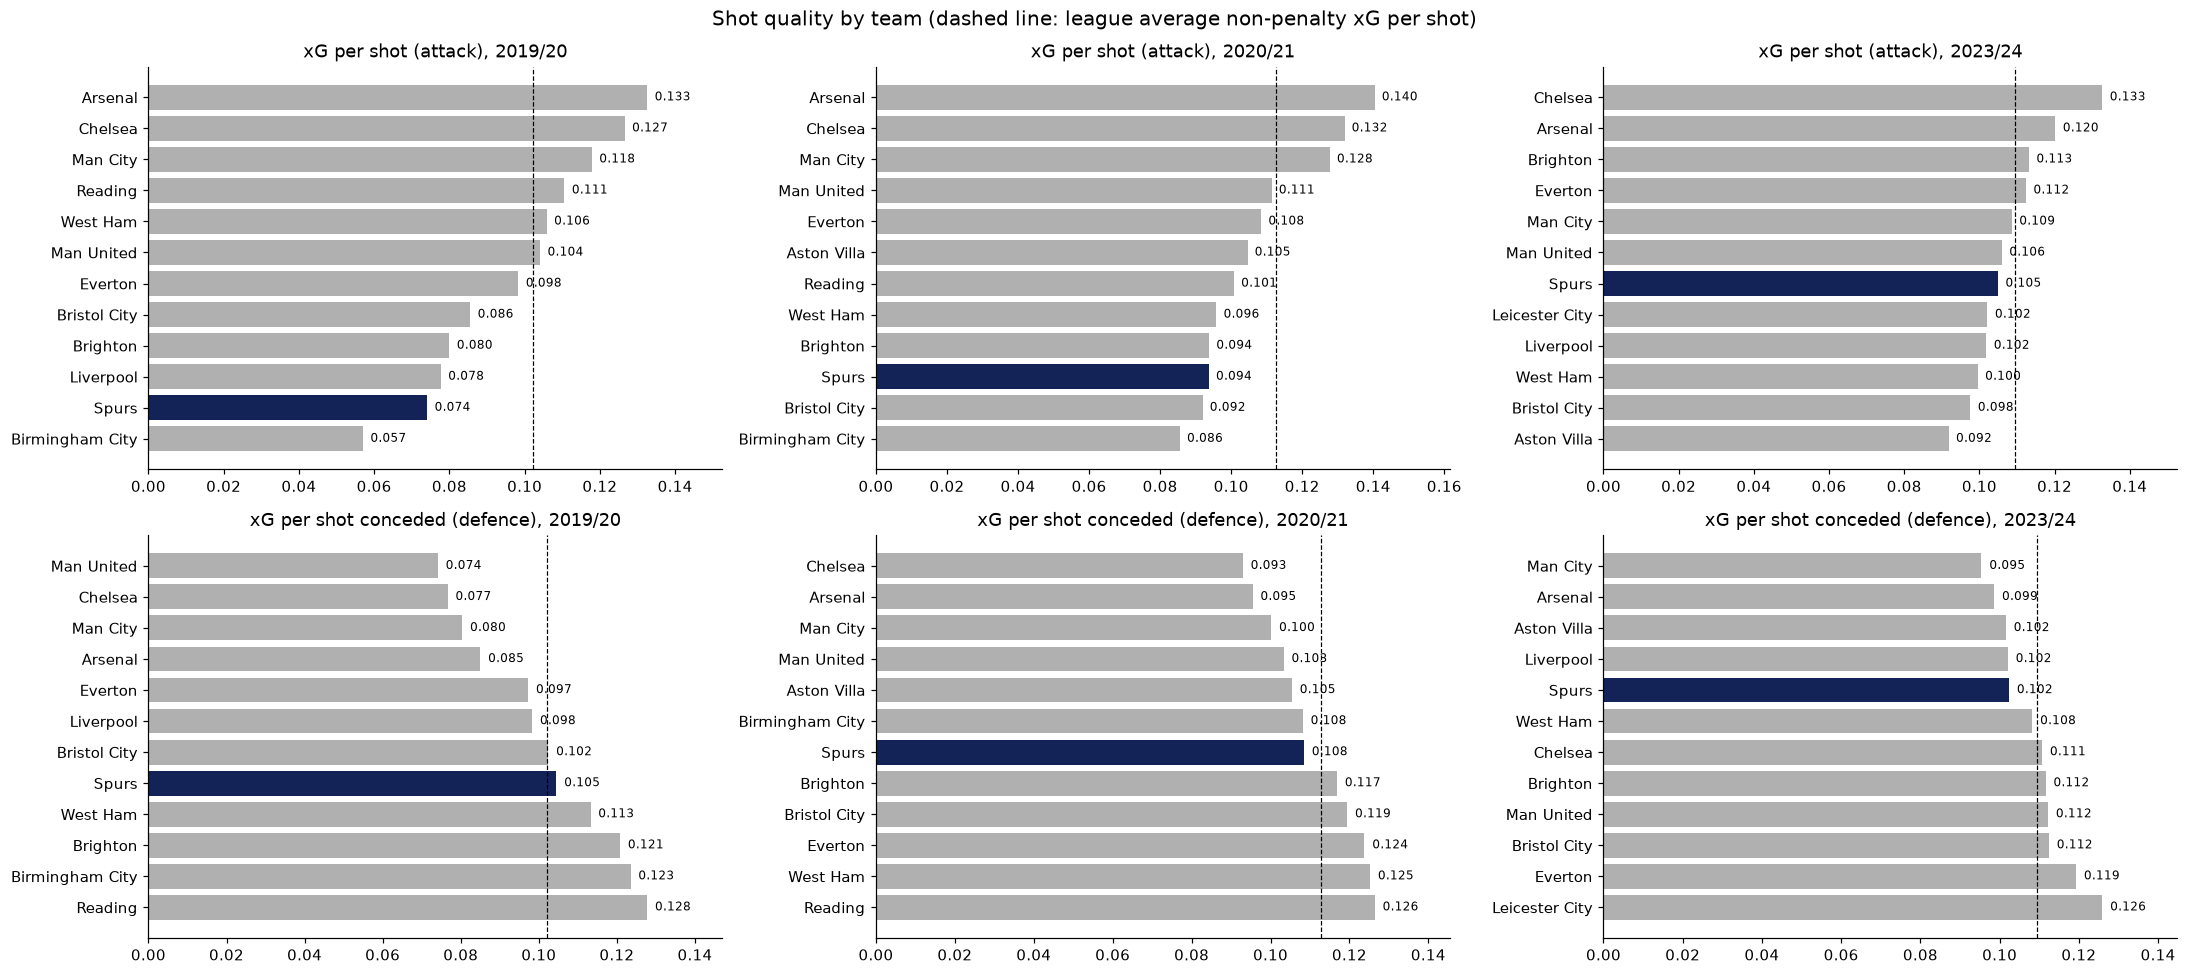

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(20, 9))
for j, season in enumerate(SEASONS):
    d = ts[ts.season == season]
    for i, (col, lab, asc) in enumerate([("xg_per_shot", "xG per shot (attack)", True),
                                          ("xg_per_shot_against", "xG per shot conceded (defence)", False)]):
        ax = axes[i, j]
        dd = d.sort_values(col, ascending=asc)
        ax.barh(dd.team, dd[col], color=[SPURS_NAVY if t == wsl.SPURS else LEAGUE_GREY for t in dd.team])
        ax.axvline(np_shots[np_shots.season == season].xg.mean(), color="black", lw=0.8, ls="--")
        for k, v in enumerate(dd[col]):
            ax.text(v + 0.002, k, f"{v:.3f}", va="center", fontsize=8)
        ax.set(title=f"{lab}, {season}", xlim=(0, d[col].max() * 1.15))
fig.suptitle("Shot quality by team (dashed line: league average non-penalty xG per shot)", fontsize=13)
fig.tight_layout(); save(fig, "04_shot_quality.png"); plt.show()

In [14]:
box = lambda d: ((d.x >= 102) & (d.y.between(18, 62))).mean()
six = lambda d: ((d.x >= 114) & (d.y.between(30, 50))).mean()
head = lambda d: (d.body_part == "Head").mean()
rows = []
for season in SEASONS:
    lg = np_shots[np_shots.season == season]
    sf, sa = lg[lg.team == wsl.SPURS], lg[lg.opponent == wsl.SPURS]
    rest = lg[(lg.team != wsl.SPURS) & (lg.opponent != wsl.SPURS)]
    for lab, d in [("Spurs shots", sf), ("Shots against Spurs", sa), ("Rest of league", rest)]:
        rows.append({"season": season, "group": lab, "shots": len(d), "xg_per_shot": d.xg.mean(),
                     "share_in_box": box(d), "share_in_six_yard_box": six(d), "share_headers": head(d),
                     "mean_distance_yds": d.distance.mean()})
shot_profile = pd.DataFrame(rows)
shot_profile.round(3).to_csv(os.path.join(RES_DIR, "shot_profile.csv"), index=False)
KEY["shot_profile"] = shot_profile.round(3).to_dict("records")
shot_profile.round(3)

,season,group,shots,xg_per_shot,share_in_box,share_in_six_yard_box,share_headers,mean_distance_yds
0,2019/20,Spurs shots,180,0.074,0.500,0.078,0.111,22.332
1,2019/20,Shots against Spurs,256,0.105,0.582,0.102,0.129,18.612
2,2019/20,Rest of league,1765,0.105,0.612,0.097,0.141,19.167
3,2020/21,Spurs shots,196,0.094,0.556,0.122,0.184,19.808
4,2020/21,Shots against Spurs,276,0.108,0.634,0.101,0.174,17.580
5,2020/21,Rest of league,2740,0.114,0.645,0.108,0.164,17.742
6,2023/24,Spurs shots,304,0.105,0.632,0.076,0.135,18.288
7,2023/24,Shots against Spurs,291,0.102,0.698,0.117,0.223,16.807
8,2023/24,Rest of league,2911,0.111,0.719,0.110,0.188,16.420


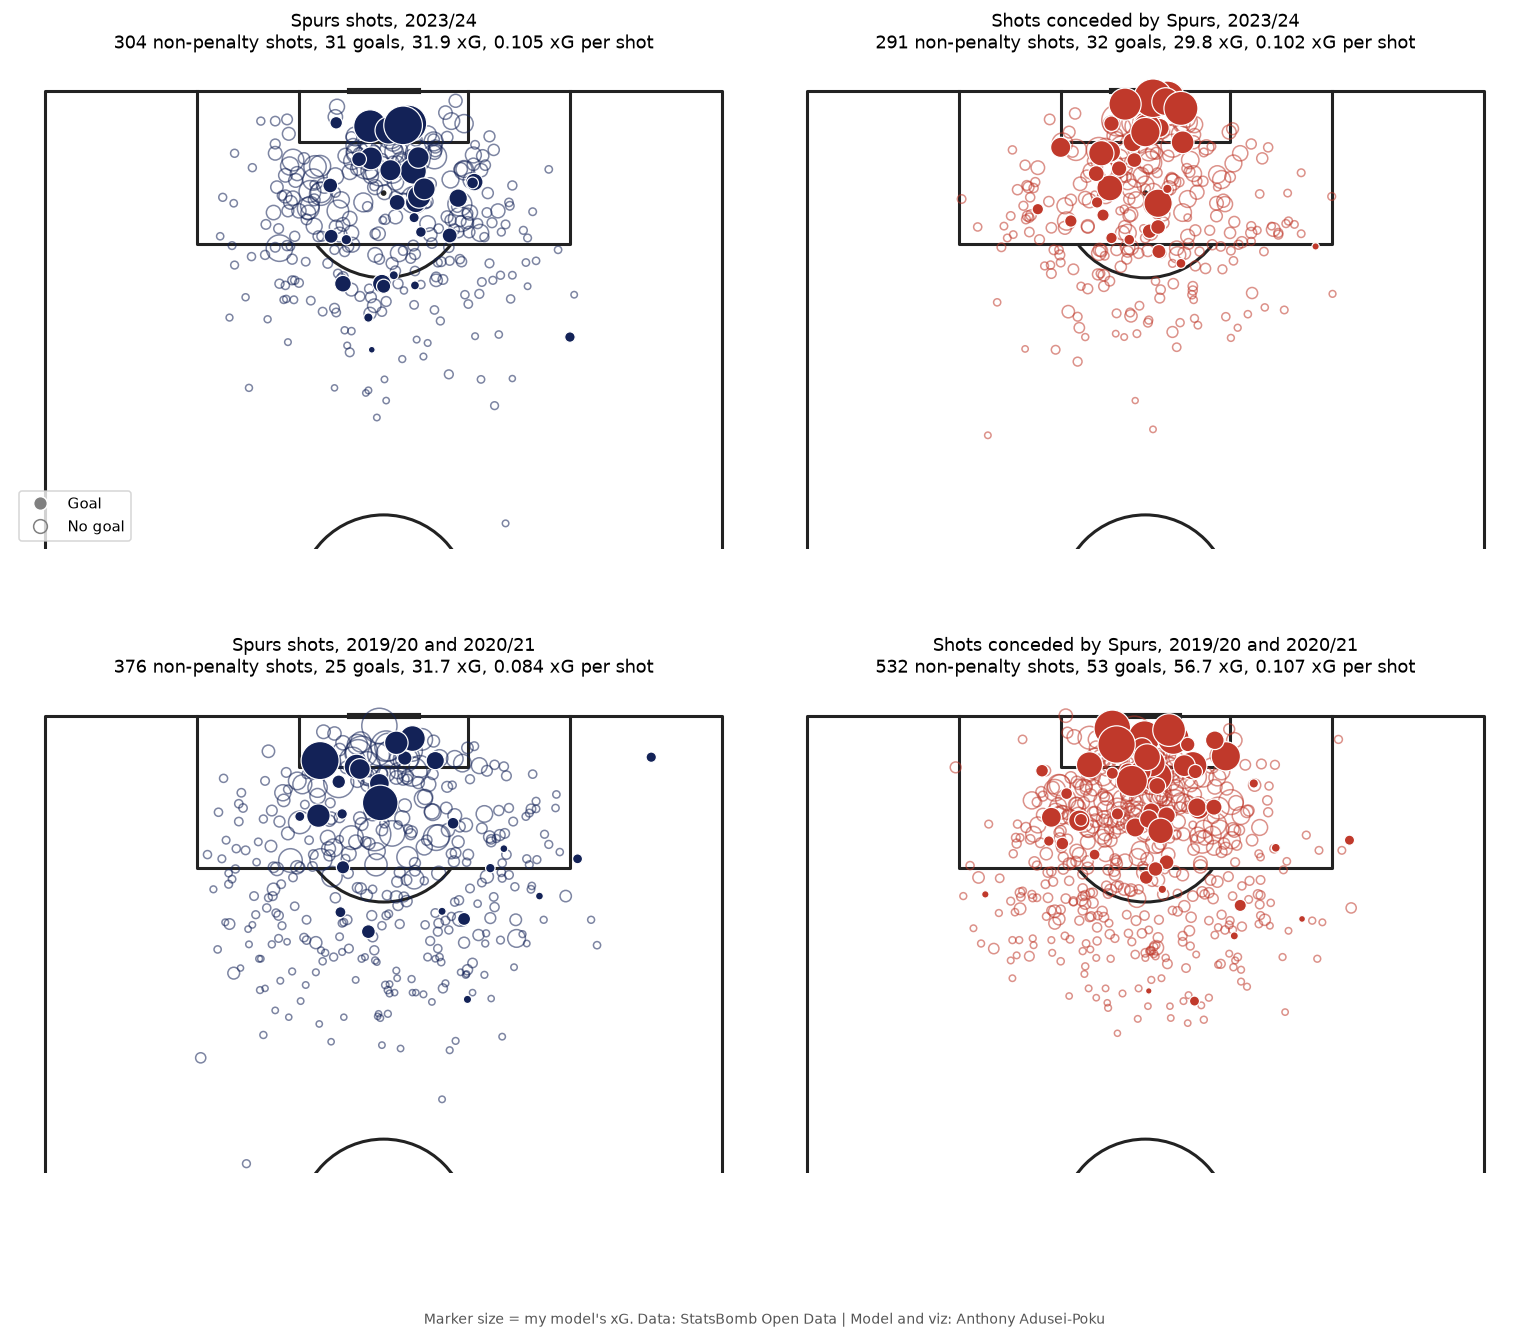

In [15]:
pitch = VerticalPitch(pitch_type="statsbomb", half=True, line_color="#222222", pad_bottom=-6)
fig, axes = pitch.draw(nrows=2, ncols=2, figsize=(14, 14))
early = np_shots.season.isin(["2019/20", "2020/21"])
latest = np_shots.season == LATEST
panels = [("Spurs shots, 2023/24", np_shots[latest & (np_shots.team == wsl.SPURS)], SPURS_NAVY),
          ("Shots conceded by Spurs, 2023/24", np_shots[latest & (np_shots.opponent == wsl.SPURS)], AGAINST_RED),
          ("Spurs shots, 2019/20 and 2020/21", np_shots[early & (np_shots.team == wsl.SPURS)], SPURS_NAVY),
          ("Shots conceded by Spurs, 2019/20 and 2020/21", np_shots[early & (np_shots.opponent == wsl.SPURS)], AGAINST_RED)]
for ax, (lab, d, col) in zip(axes.flat, panels):
    gl = d.is_goal == 1
    pitch.scatter(d.x[~gl], d.y[~gl], s=d.xg[~gl] * 700 + 10, ax=ax, facecolors="none", edgecolors=col, lw=1, alpha=0.55)
    pitch.scatter(d.x[gl], d.y[gl], s=d.xg[gl] * 700 + 10, ax=ax, c=col, edgecolors="white", lw=0.8, zorder=3)
    ax.set_title(f"{lab}\n{len(d)} non-penalty shots, {int(d.is_goal.sum())} goals, "
                 f"{d.xg.sum():.1f} xG, {d.xg.mean():.3f} xG per shot", fontsize=11.5)
leg = [Line2D([0], [0], marker="o", ls="", markerfacecolor="grey", markeredgecolor="white", ms=9, label="Goal"),
       Line2D([0], [0], marker="o", ls="", markerfacecolor="none", markeredgecolor="grey", ms=9, label="No goal")]
axes.flat[0].legend(handles=leg, loc="lower left")
fig.text(0.5, 0.04, "Marker size = my model's xG. Data: StatsBomb Open Data | Model and viz: Anthony Adusei-Poku",
         ha="center", fontsize=9, color="#555555")
save(fig, "05_spurs_shotmap.png"); plt.show()

### Chance creation

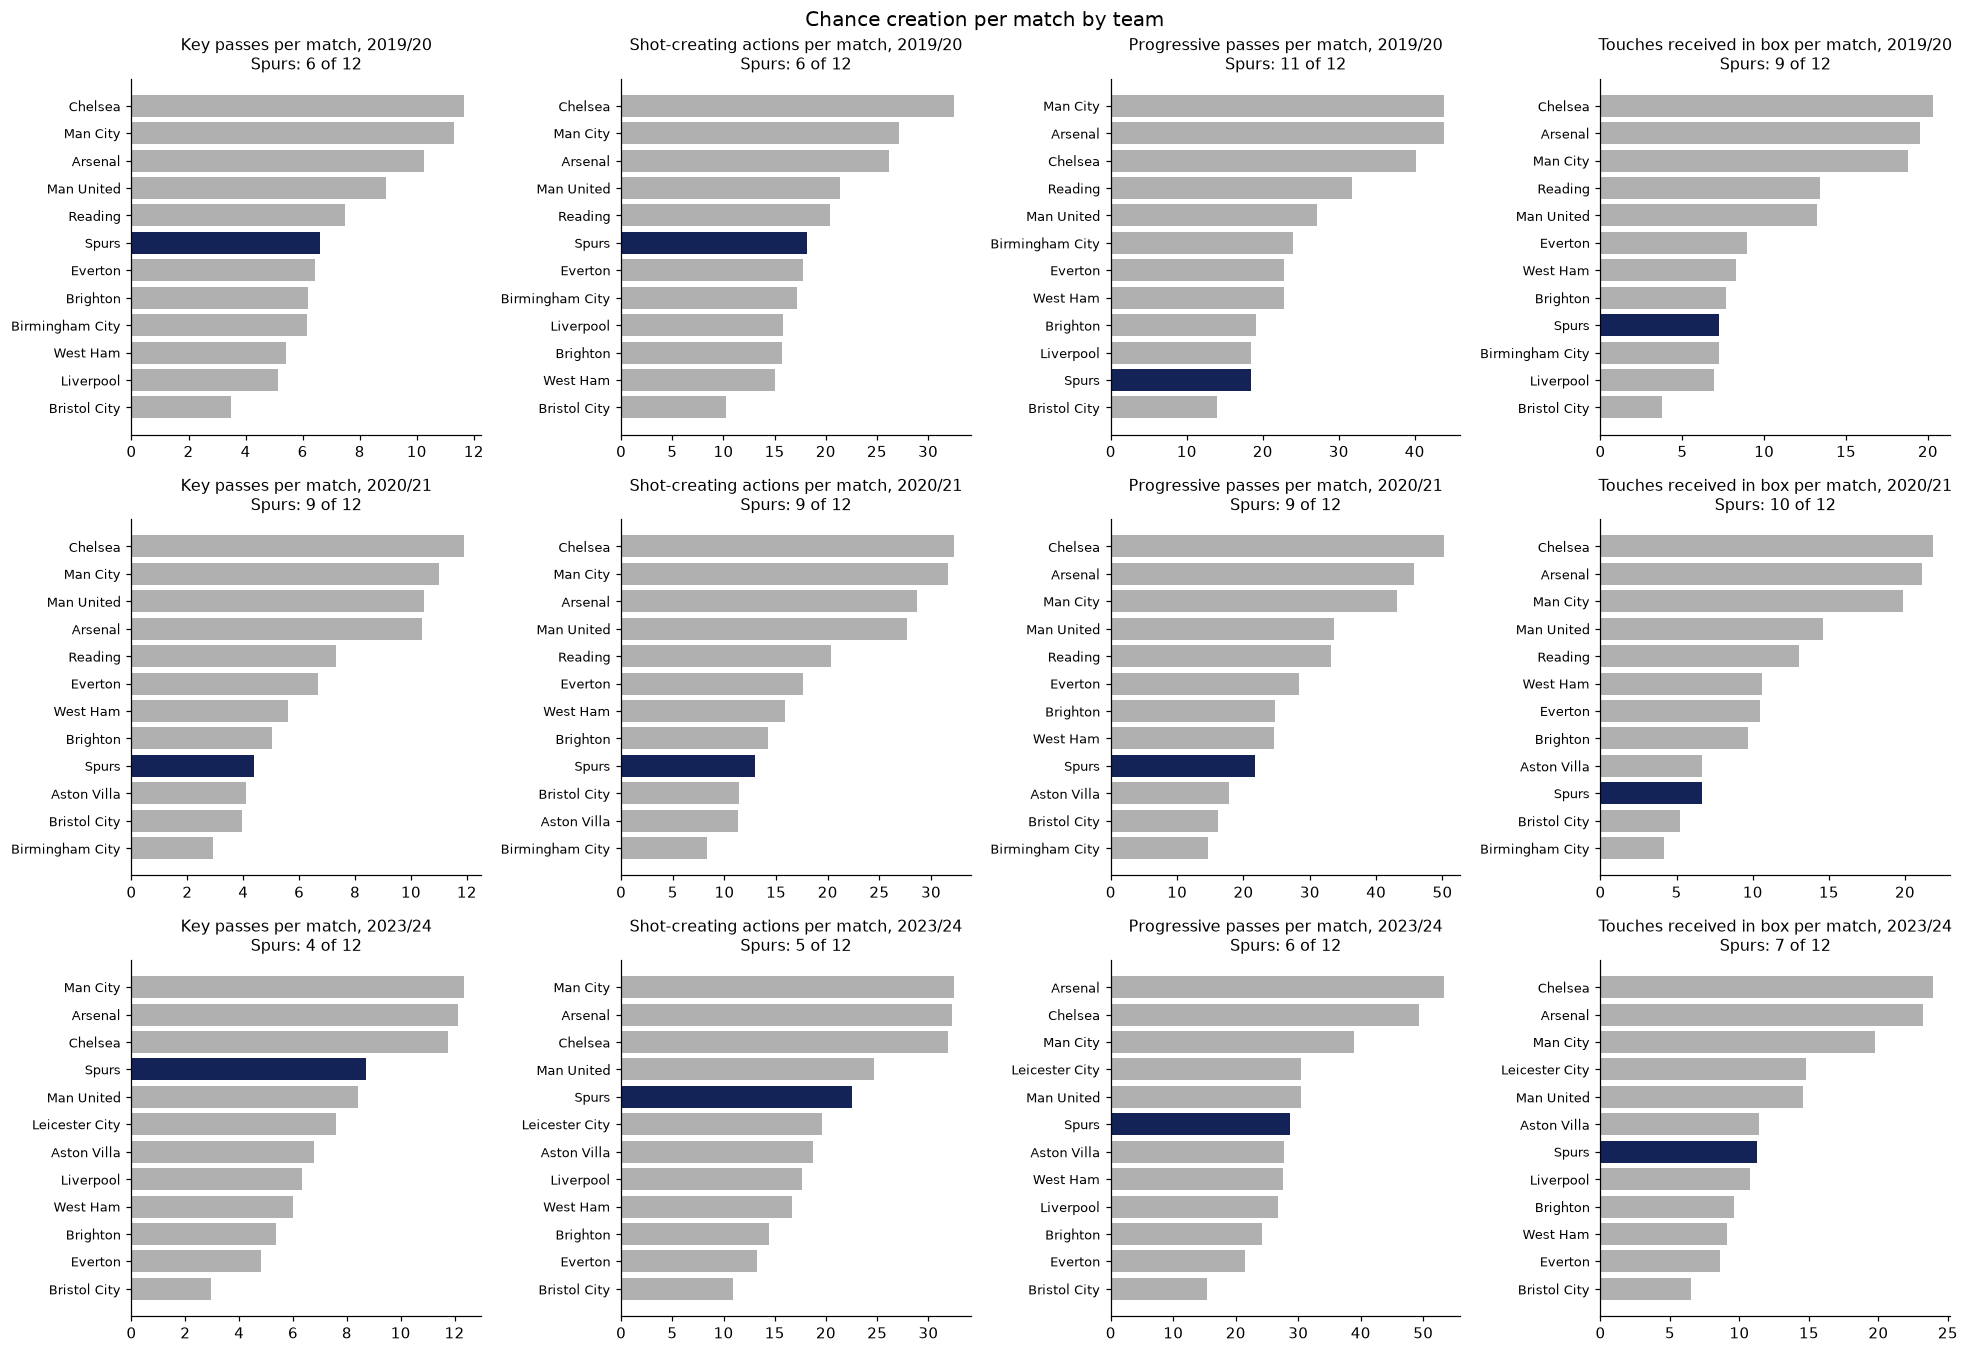

In [16]:
cc = {"key_passes_pm": "Key passes", "sca_pm": "Shot-creating actions", "prog_passes_pm": "Progressive passes",
      "box_receipts_pm": "Touches received in box"}
fig, axes = plt.subplots(3, 4, figsize=(18, 12.5))
for i, season in enumerate(SEASONS):
    d = ts[ts.season == season]
    for j, (col, lab) in enumerate(cc.items()):
        ax = axes[i, j]
        dd = d.sort_values(col)
        ax.barh(dd.team, dd[col], color=[SPURS_NAVY if t == wsl.SPURS else LEAGUE_GREY for t in dd.team])
        rk = int(d.loc[d.team == wsl.SPURS, col + "_rank"].iloc[0])
        ax.set_title(f"{lab} per match, {season}\nSpurs: {rk} of {len(d)}", fontsize=10.5)
        ax.tick_params(axis="y", labelsize=8.5)
fig.suptitle("Chance creation per match by team", fontsize=13)
fig.tight_layout(); save(fig, "06_chance_creation.png"); plt.show()

## 4. Player radars

Per-90 profiles are built per player per season from StatsBomb event data, with a **minimum of 900 WSL minutes** in the data for that season. Each player is placed in the position group where she played most minutes, and each metric is shown as a **percentile against every WSL player-season in the same group** across **all four seasons in the data (2018/19, 2019/20, 2020/21 and 2023/24)**; pooling gives bigger peer groups. As a check, `results/spurs_player_radars.csv` also has each percentile against 2023/24 player-seasons only. Defensive counts are possession-adjusted (PAdj) and success rates are shrunk towards the league rate, as in football-scouting-tool. Player xG here is StatsBomb's, as in the scouting tool, so the radars do not depend on my model.

I picked six regular starters from 2023/24, the most recent season, one or two per position group.

In [17]:
prof = wsl.build_profiles(player_match, min_minutes=900)
print("Player-seasons with 900+ minutes by position group:", prof.group.value_counts().to_dict())
spurs_prof = prof[prof.team == wsl.SPURS].sort_values(["season", "minutes"], ascending=[True, False])
spurs_prof[["season", "name", "group", "minutes", "np_goals", "npxg", "key_passes", "sca"]].round(1)

Player-seasons with 900+ minutes by position group: {'CM': 120, 'CB': 113, 'AM/W': 112, 'FB': 96, 'ST': 46}


,season,name,group,minutes,np_goals,npxg,key_passes,sca
285,2019/20,Ria Percival,CM,1342.2,0.0,0.4,8.0,24.0
402,2019/20,Hannah Godfrey,CB,1340.4,0.0,0.5,6.0,9.0
221,2019/20,Rachel Furness,CM,1231.2,4.0,2.2,14.0,35.0
422,2019/20,Anna Filbey,CB,1218.4,0.0,0.0,4.0,10.0
420,2019/20,Rianna Dean,ST,1197.3,2.0,4.5,3.0,11.0
41,2019/20,Josie Green,CM,1184.9,0.0,0.4,11.0,22.0
38,2019/20,Ashleigh Neville,FB,1170.3,0.0,0.8,6.0,17.0
400,2019/20,Kit Graham,AM/W,1133.3,3.0,2.2,17.0,41.0
234,2019/20,Gemma Davison,AM/W,935.5,0.0,0.4,9.0,36.0
50,2020/21,Shelina Zadorsky,CB,1897.3,0.0,0.3,1.0,11.0


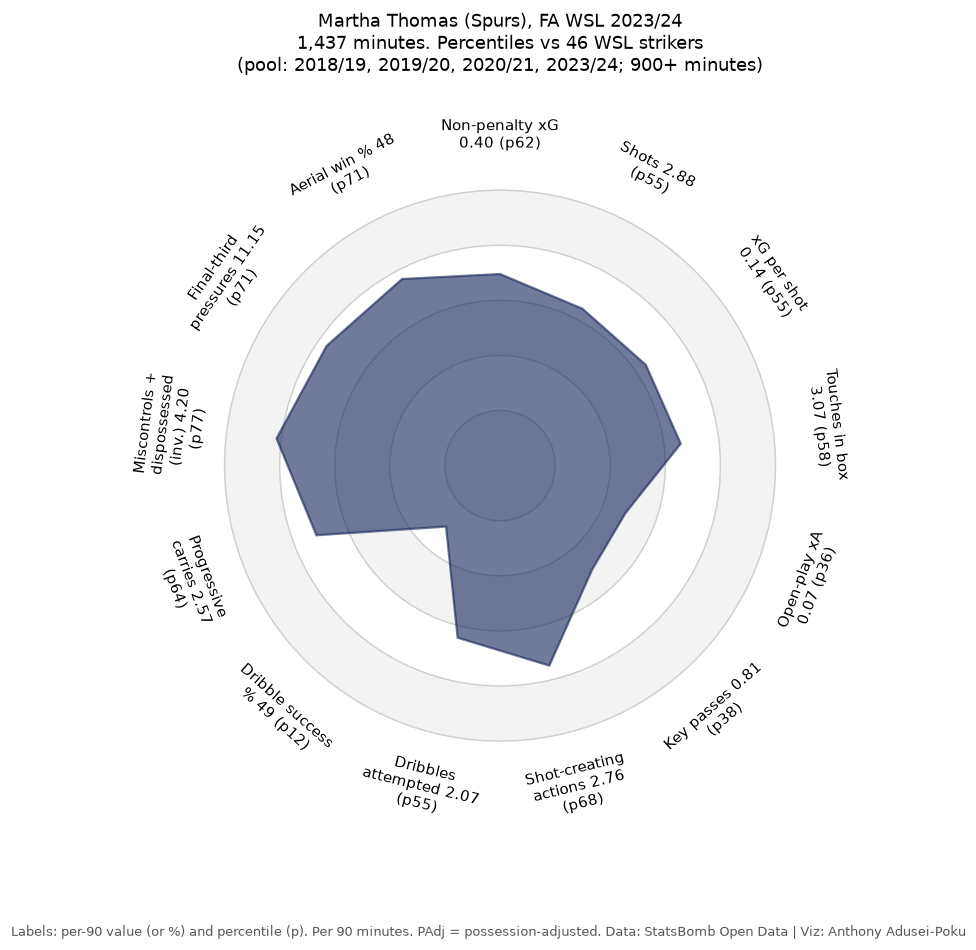

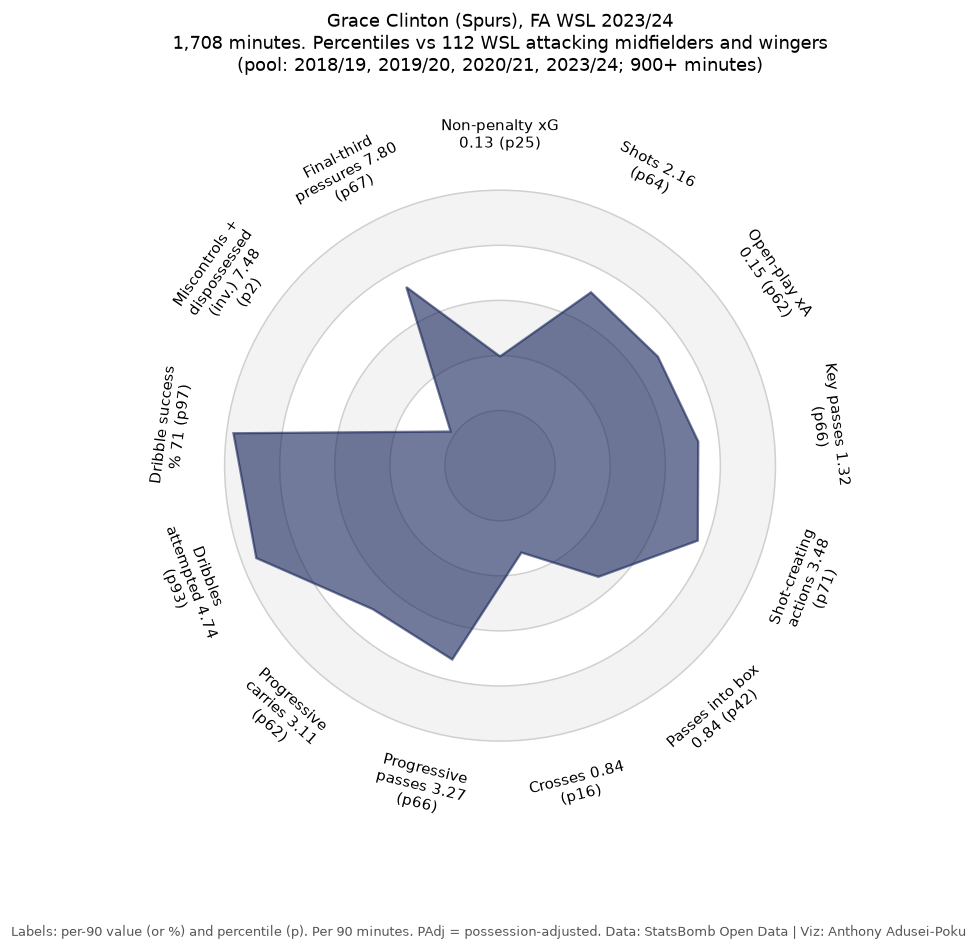

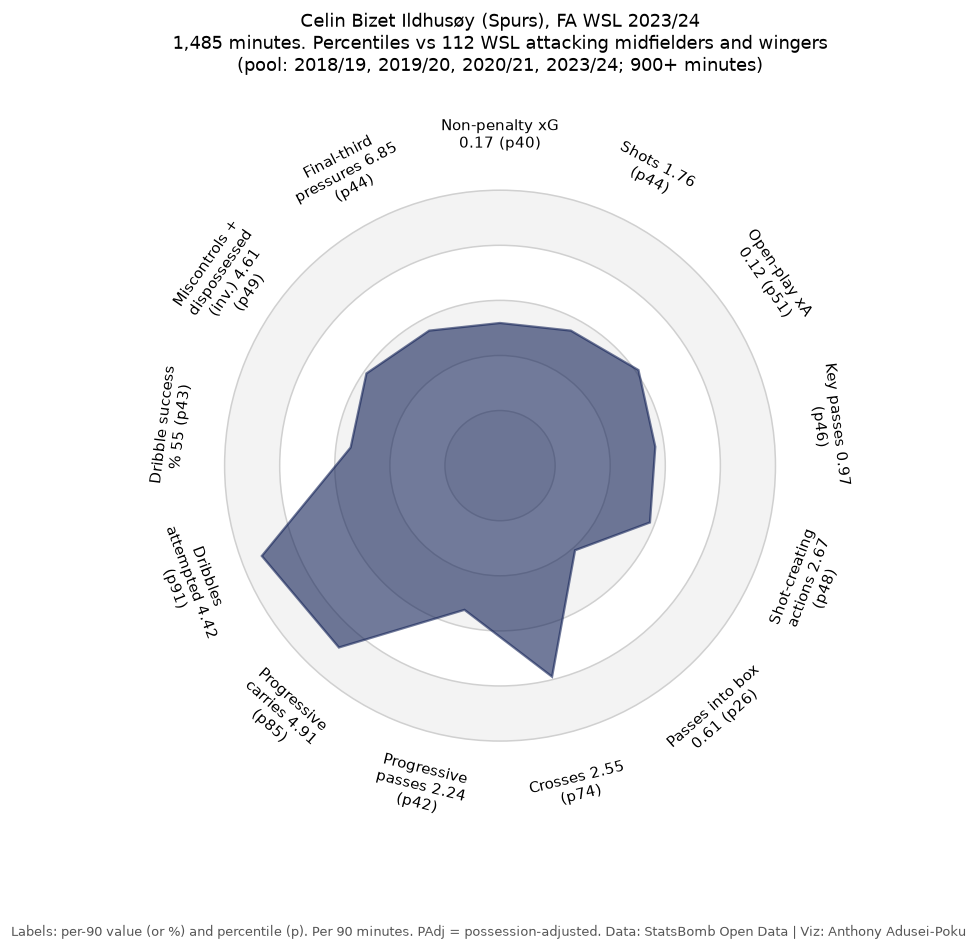

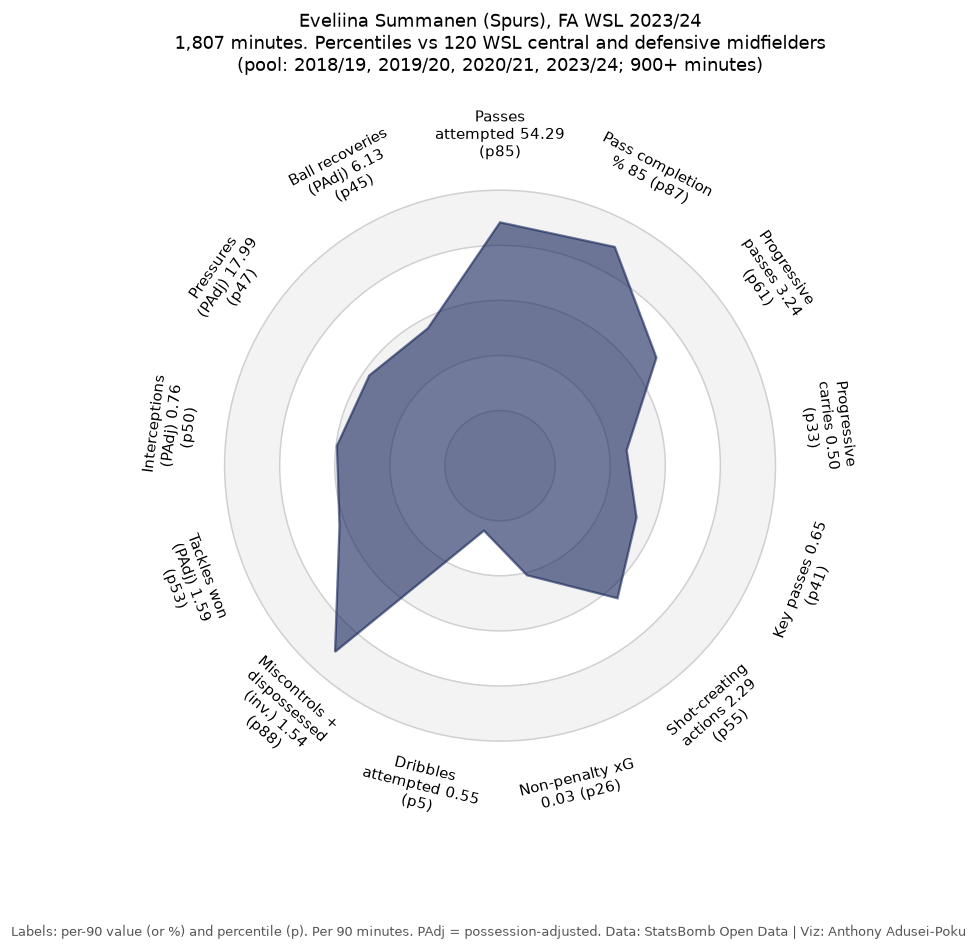

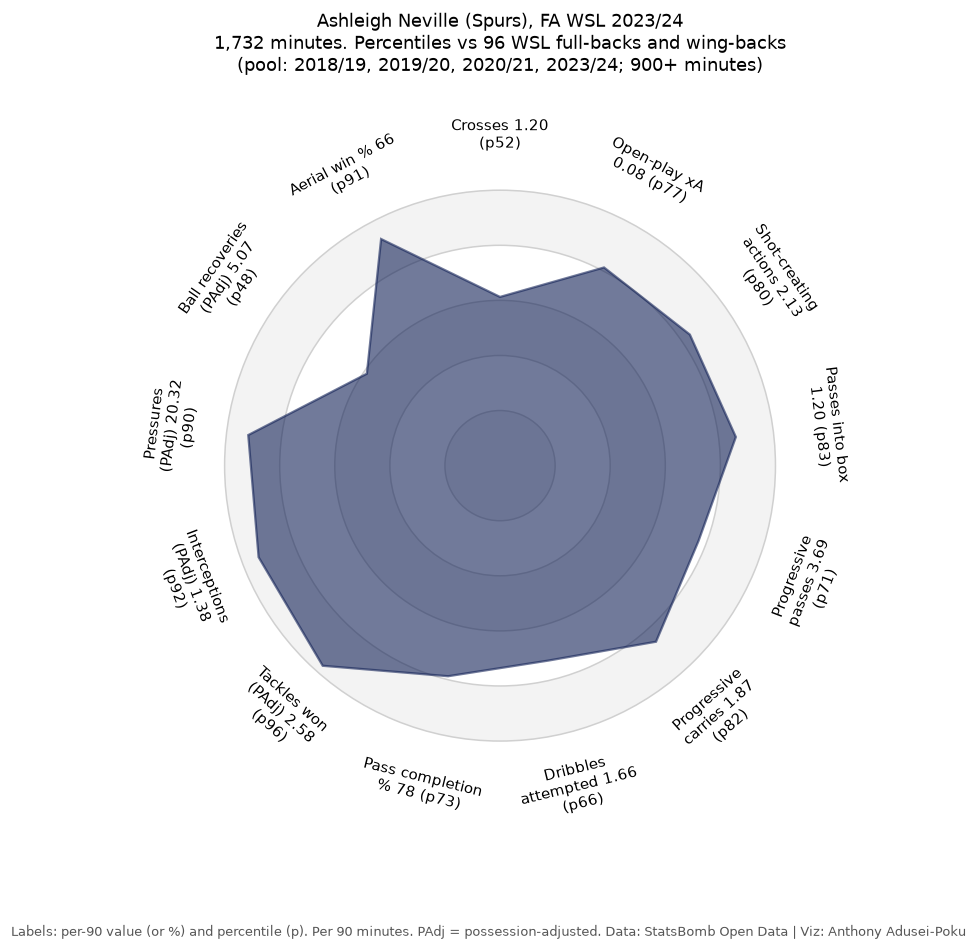

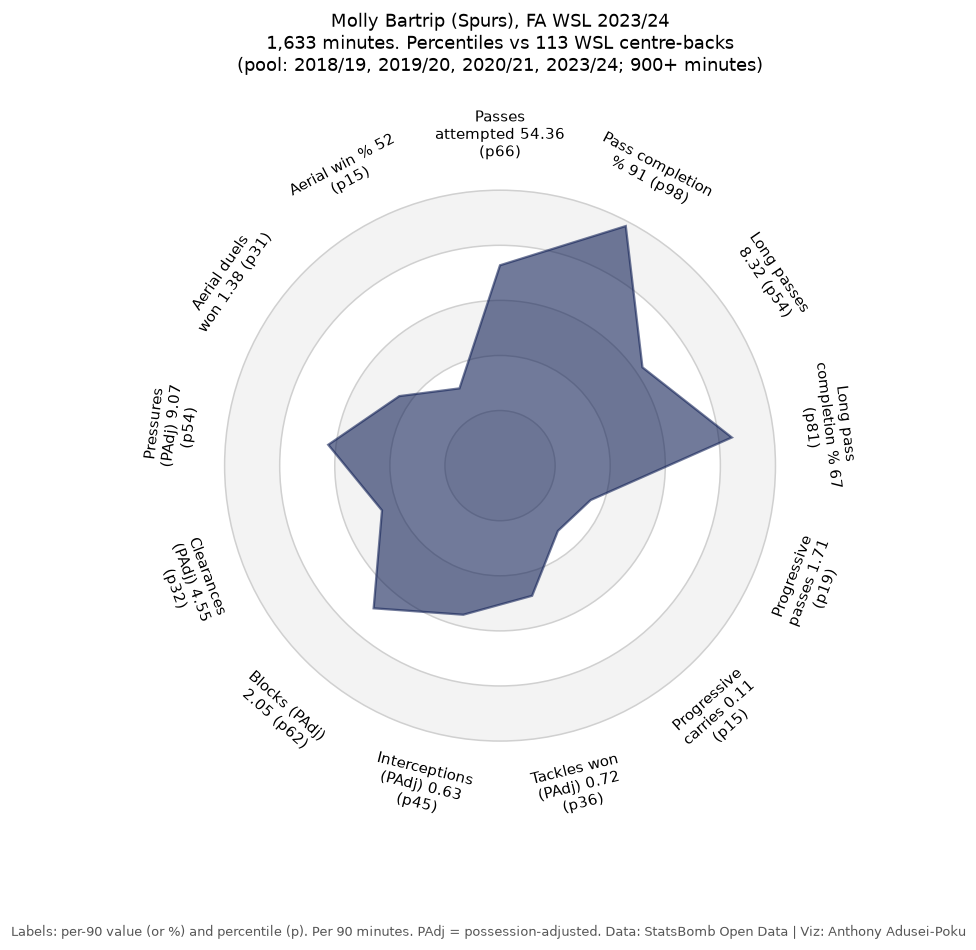

In [18]:
PICKS = {"Martha Thomas": "thomas", "Grace Clinton": "clinton", "Celin Bizet Ildhusøy": "bizet",
         "Eveliina Summanen": "summanen", "Ashleigh Neville": "neville", "Molly Bartrip": "bartrip"}
sel = prof[(prof.team == wsl.SPURS) & (prof.season == LATEST) & prof.name.isin(PICKS)]
assert len(sel) == len(PICKS), sel.name.tolist()
radar_rows = []

def draw_radar(idx, fname):
    row = prof.loc[idx]
    pct = wsl.percentiles(prof, idx)
    cols = wsl.RADAR[row.group]
    fmt = lambda c: f"{row[c]:.0f}" if c.endswith("pct") else f"{row[c]:.2f}"
    params = [f"{wsl.FEATURES[c]}{' (inv.)' if c in wsl.LOWER_IS_BETTER else ''} {fmt(c)} (p{pct[c]:.0f})"
              for c in cols]
    radar = Radar(params, [0] * len(params), [100] * len(params), round_int=[True] * len(params),
                  num_rings=4, ring_width=1, center_circle_radius=1)
    fig, ax = radar.setup_axis(figsize=(8.4, 9))
    radar.draw_circles(ax=ax, facecolor="#f3f3f3", edgecolor="#d0d0d0")
    radar.draw_radar_solid(list(pct.values()), ax=ax, kwargs={"facecolor": SPURS_NAVY, "alpha": 0.6,
                                                              "edgecolor": SPURS_NAVY, "lw": 1.5})
    radar.draw_param_labels(ax=ax, fontsize=9.5)
    n_peers = (prof.group == row.group).sum()
    ax.set_title(f"{row['name']} (Spurs), FA WSL {row.season}\n{row.minutes:,.0f} minutes. Percentiles vs {n_peers} "
                 f"WSL {wsl.GROUP_LABEL[row.group]}\n(pool: 2018/19, 2019/20, 2020/21, 2023/24; 900+ minutes)", fontsize=12, pad=24)
    fig.text(0.5, 0.02, "Labels: per-90 value (or %) and percentile (p). Per 90 minutes. PAdj = possession-adjusted. Data: StatsBomb Open Data | Viz: Anthony Adusei-Poku",
             ha="center", fontsize=8.5, color="#555555")
    save(fig, fname); plt.show()
    latest_only = wsl.percentiles(prof[prof.season == LATEST], idx)
    radar_rows.append({"player": row["name"], "season": row.season, "group": row.group, "minutes": round(row.minutes),
                       "peers": int(n_peers), "peers_2023_24": int(((prof.group == row.group) & (prof.season == LATEST)).sum()),
                       **{c: round(row[c], 3) for c in cols},
                       **{c + "_pct": round(v) for c, v in pct.items()},
                       **{c + "_pct_2023_24_only": round(v) for c, v in latest_only.items()}})

for k, (name, slug) in enumerate(PICKS.items(), start=7):
    idx = sel.index[sel.name == name][0]
    draw_radar(idx, f"{k:02d}_radar_{slug}.png")

In [19]:
rad = pd.DataFrame(radar_rows)
rad.to_csv(os.path.join(RES_DIR, "spurs_player_radars.csv"), index=False)
KEY["radars"] = rad.where(pd.notna(rad), None).to_dict("records")
top = []
for _, rw in rad.iterrows():
    pcts = {c: rw[c + "_pct"] for c in wsl.RADAR[rw.group]}
    best = sorted(pcts.items(), key=lambda kv: -kv[1])[:3]
    top.append({"player": rw.player, "group": rw.group, "minutes": rw.minutes,
                "top_three": ", ".join(f"{wsl.FEATURES[c]} {rw[c]:.2f} (percentile {v:.0f})" for c, v in best)})
pd.DataFrame(top)

,player,group,minutes,top_three
0,Martha Thomas,ST,1437,Miscontrols + dispossessed 4.20 (percentile 77...
1,Grace Clinton,AM/W,1708,"Dribble success % 70.99 (percentile 97), Dribb..."
2,Celin Bizet Ildhusøy,AM/W,1485,"Dribbles attempted 4.42 (percentile 91), Progr..."
3,Eveliina Summanen,CM,1807,Miscontrols + dispossessed 1.54 (percentile 88...
4,Ashleigh Neville,FB,1732,"Tackles won (PAdj) 2.58 (percentile 96), Inter..."
5,Molly Bartrip,CB,1633,"Pass completion % 91.02 (percentile 98), Long ..."


In [20]:
with open(os.path.join(RES_DIR, "key_numbers.json"), "w") as fh:
    json.dump(KEY, fh, indent=1, default=float)
print("Saved results/key_numbers.json")

Saved results/key_numbers.json


## 5. Conclusions

* **Coverage:** 457 WSL matches: 107 of 110 in 2018/19, all 87 played in the curtailed 2019/20, 131 of 132 in 2020/21 and all 132 in 2023/24. Spurs: 15 of 15 in 2019/20, 21 of 22 in 2020/21 and 22 of 22 in 2023/24.
* **Model transfer:** trained only on 57,664 men's shots, my xG model gave 1,279.4 xG for 1,300 goals on 11,711 WSL non-penalty shots (StatsBomb: 1,230.0), with log loss 0.2915 against 0.2951 for StatsBomb. It over-rates the biggest chances (226 goals from 235.5 xG on shots valued at 0.45 or more).
* **2023/24 was Spurs' best season in the data:** npxG difference +0.10 a match (5th of 12), the first positive figure in their three seasons here, after −0.89 (11th) in 2019/20 and −0.55 (7th) in 2020/21. npxG for rose to 1.45 a match (5th).
* **Creation improved most:** 8.7 key passes (4th), 22.5 shot-creating actions (5th) and 28.6 progressive passes (6th) a match in 2023/24, against 4.4, 13.0 and 21.7 in 2020/21.
* **Shot quality is still below the league:** 0.105 xG per shot in 2023/24 (7th), with 63.2% of shots from inside the box against 71.9% for the rest of the league.
* **Players (2023/24):** Grace Clinton 3.48 shot-creating actions per 90 and 71% dribble success (97th percentile); Ashleigh Neville 96th percentile for tackles won (PAdj) and 92nd for interceptions; Martha Thomas 7 non-penalty goals from 6.5 StatsBomb npxG.

**Limitations:** 2023/24 is still not the current season, samples are small (at most 22 matches a season), one Spurs match from 2020/21 is missing, the xG model was trained on men's football, and shot-creating actions and progressive passes are my own implementations. See the README for the full list.